# Laboratorio Final — Starbucks Rewards
## Notebook resuelto: T-learner, curva Qini y políticas de contacto

Este notebook resuelve la lógica de `streamlit_starter.py` con el archivo `uplift_experiment.csv`.

**Objetivo de negocio:** comparar el contacto aleatorio, el contacto por riesgo de no responder y el contacto por uplift estimado. El conjunto de prueba queda separado del entrenamiento.

Coloca `uplift_experiment.csv` junto al notebook antes de ejecutarlo.

In [2]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split

FEATURES = ["recency_days", "frequency", "monetary", "email_open_rate"]
RANDOM_STATE = 42

csv_path = Path("uplift_experiment.csv")
if not csv_path.exists():
    csv_path = Path("uplift_experiment.csv")
df = pd.read_csv(csv_path)

required = FEATURES + ["treatment_group", "responded_90d", "value_90d"]
missing = [c for c in required if c not in df.columns]
if missing:
    raise ValueError(f"Faltan columnas requeridas: {missing}")

print(f"{len(df):,} clientes")
print(df["treatment_group"].value_counts())
display(df.head())

14,000 clientes
treatment_group
control      7096
treatment    6904
Name: count, dtype: int64


,customer_id,treatment_group,recency_days,frequency,monetary,email_open_rate,responded_90d,value_90d,true_type,true_uplift_prob,true_uplift_value
0,1,control,9,15,437.41,1.000,1,26.24,sure_thing,0.03,0.72
1,2,control,59,7,159.66,0.217,0,0.00,persuadable,0.58,13.34
2,3,control,106,8,172.83,0.300,0,0.00,persuadable,0.58,13.34
3,4,treatment,181,1,57.46,0.018,0,0.00,lost_cause,0.02,0.18
4,5,treatment,146,3,44.61,0.124,0,0.00,lost_cause,0.02,0.18


## 1. Separación de entrenamiento y prueba

Separamos el 70% para entrenar y el 30% para evaluar. La estratificación conserva la proporción de tratados y controles.

In [3]:
train, test = train_test_split(
    df, test_size=0.30, random_state=RANDOM_STATE,
    stratify=df["treatment_group"]
)
train = train.copy()
test = test.copy()
print(f"Entrenamiento: {len(train):,} | Prueba: {len(test):,}")

Entrenamiento: 9,800 | Prueba: 4,200


## 2. Entrenar el T-learner y el modelo de riesgo

El T-learner entrena dos regresiones logísticas: una con tratados y otra con controles. El modelo de riesgo predice la no respuesta, mezclando ambos grupos de entrenamiento.

In [4]:
train_t = train[train["treatment_group"] == "treatment"]
train_c = train[train["treatment_group"] == "control"]

modelo_tratado = LogisticRegression(max_iter=1000)
modelo_tratado.fit(train_t[FEATURES], train_t["responded_90d"])

modelo_control = LogisticRegression(max_iter=1000)
modelo_control.fit(train_c[FEATURES], train_c["responded_90d"])

train_riesgo = train.copy()
train_riesgo["churned"] = 1 - train_riesgo["responded_90d"]
modelo_riesgo = LogisticRegression(max_iter=1000)
modelo_riesgo.fit(train_riesgo[FEATURES], train_riesgo["churned"])

X_test = test[FEATURES]
test["p_tratado"] = modelo_tratado.predict_proba(X_test)[:, 1]
test["p_control"] = modelo_control.predict_proba(X_test)[:, 1]
test["uplift_estimado"] = test["p_tratado"] - test["p_control"]
test["prob_churn"] = modelo_riesgo.predict_proba(X_test)[:, 1]

display(test[["p_tratado", "p_control", "uplift_estimado", "prob_churn"]].describe().round(3))

,p_tratado,p_control,uplift_estimado,prob_churn
count,4200.000,4200.000,4200.000,4200.000
mean,0.458,0.314,0.144,0.616
std,0.290,0.266,0.121,0.271
min,0.024,0.018,-0.261,0.072
25%,0.167,0.082,0.052,0.401
50%,0.458,0.244,0.113,0.635
75%,0.736,0.467,0.214,0.876
max,0.958,0.953,0.585,0.975


## 3. Curva Qini

Para cada prefijo de la lista ordenada, se calcula la diferencia entre la tasa de respuesta de tratados y controles y se multiplica por el tamaño del prefijo. El coeficiente se calcula como el área sobre la referencia aleatoria, normalizada por el tamaño de prueba.

/tmp/ipykernel_695/1053341149.py:22: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  area_modelo = np.trapz(ys, xs)
/tmp/ipykernel_695/1053341149.py:23: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  area_azar = np.trapz(np.linspace(0, ys[-1], len(xs)), xs)


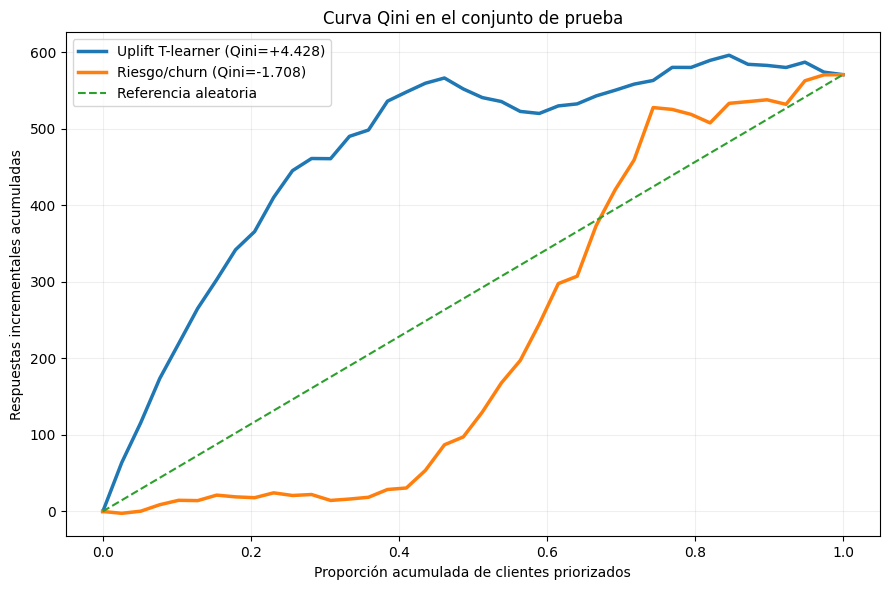

Coeficiente Qini · uplift: +4.4278
Coeficiente Qini · riesgo/churn: -1.7077


In [5]:
def curva_qini(test_df, score_col, steps=40):
    orden = test_df.sort_values(score_col, ascending=False).reset_index(drop=True)
    es_tratado = (orden["treatment_group"] == "treatment").to_numpy()
    respondio = orden["responded_90d"].to_numpy()

    acum_t = np.cumsum(np.where(es_tratado, respondio, 0))
    acum_c = np.cumsum(np.where(~es_tratado, respondio, 0))
    n_t = np.cumsum(es_tratado)
    n_c = np.cumsum(~es_tratado)

    n = len(orden)
    xs, ys = [0.0], [0.0]
    for i in np.unique(np.linspace(1, n, steps).astype(int)):
        tasa_t = acum_t[i - 1] / n_t[i - 1] if n_t[i - 1] else 0.0
        tasa_c = acum_c[i - 1] / n_c[i - 1] if n_c[i - 1] else 0.0
        xs.append(i / n)
        ys.append((tasa_t - tasa_c) * i)
    return np.asarray(xs), np.asarray(ys)


def coeficiente_qini(xs, ys):
    area_modelo = np.trapz(ys, xs)
    area_azar = np.trapz(np.linspace(0, ys[-1], len(xs)), xs)
    return (area_modelo - area_azar) / max(len(ys) - 1, 1)


xs_uplift, ys_uplift = curva_qini(test, "uplift_estimado")
xs_riesgo, ys_riesgo = curva_qini(test, "prob_churn")
qini_uplift = coeficiente_qini(xs_uplift, ys_uplift)
qini_riesgo = coeficiente_qini(xs_riesgo, ys_riesgo)

fig, ax = plt.subplots(figsize=(9, 6))
ax.plot(xs_uplift, ys_uplift, linewidth=2.5, label=f"Uplift T-learner (Qini={qini_uplift:+.3f})")
ax.plot(xs_riesgo, ys_riesgo, linewidth=2.5, label=f"Riesgo/churn (Qini={qini_riesgo:+.3f})")
ax.plot([0, 1], [0, ys_uplift[-1]], linestyle="--", label="Referencia aleatoria")
ax.set_xlabel("Proporción acumulada de clientes priorizados")
ax.set_ylabel("Respuestas incrementales acumuladas")
ax.set_title("Curva Qini en el conjunto de prueba")
ax.grid(alpha=0.2)
ax.legend()
plt.tight_layout()
plt.show()

print(f"Coeficiente Qini · uplift: {qini_uplift:+.4f}")
print(f"Coeficiente Qini · riesgo/churn: {qini_riesgo:+.4f}")

## 4. Tabla de políticas para el porcentaje elegido

Por defecto se contacta al 30% de la prueba. El valor incremental observado es la media de `value_90d` entre tratados menos la media entre controles dentro de cada grupo seleccionado.

In [6]:
def valor_de_la_politica(test_df, seleccionados):
    sel = test_df.loc[seleccionados]
    valores_t = sel.loc[sel["treatment_group"] == "treatment", "value_90d"]
    valores_c = sel.loc[sel["treatment_group"] == "control", "value_90d"]
    if valores_t.empty or valores_c.empty:
        return np.nan, len(sel)
    return valores_t.mean() - valores_c.mean(), len(sel)


pct_contactar = 30
n_contactar = max(2, int(len(test) * pct_contactar / 100))
idx_azar = test.sample(n=n_contactar, random_state=RANDOM_STATE).index
idx_riesgo = test.sort_values("prob_churn", ascending=False).head(n_contactar).index
idx_uplift = test.sort_values("uplift_estimado", ascending=False).head(n_contactar).index

filas = []
for nombre, idx in [
    ("Contacto aleatorio", idx_azar),
    ("Mayor riesgo de no responder", idx_riesgo),
    ("Mayor uplift estimado (T-learner)", idx_uplift),
]:
    valor_cliente, n_sel = valor_de_la_politica(test, idx)
    filas.append({
        "politica": nombre,
        "clientes_seleccionados": n_sel,
        "valor_incremental_por_cliente": valor_cliente,
        "valor_incremental_total": valor_cliente * n_sel if pd.notna(valor_cliente) else np.nan,
    })

tabla_politicas = pd.DataFrame(filas)
display(tabla_politicas.round(2))

,politica,clientes_seleccionados,valor_incremental_por_cliente,valor_incremental_total
0,Contacto aleatorio,1260,3.20,4027.26
1,Mayor riesgo de no responder,1260,0.17,219.73
2,Mayor uplift estimado (T-learner),1260,8.19,10318.67


## 5. Lectura para negocio

- **Uplift** intenta identificar a las personas cuya probabilidad de responder aumenta con la oferta.
- **Riesgo/churn** encuentra a quienes probablemente no responderán; no implica que sean persuadibles.
- Compara el Qini y el valor incremental total de la tabla antes de elegir una política.
- Los valores son estimaciones basadas en el conjunto de prueba, no una garantía de resultados futuros.
- La calidad de estas comparaciones depende del tamaño de la muestra y de que el experimento haya asignado tratamiento y control de forma adecuada.